Autor: Marko Aleksandrovic

# Predikcija cene polovnih automobila

## 1. Eksplorativna analiza podataka (EDA)

### Cilj analize

Cilj ovog projekta je razvoj regresionog modela mašinskog učenja koji predviđa cenu polovnih automobila na osnovu njihovih karakteristika.

Ciljna promenljiva je `priceUSD`, koja predstavlja cenu automobila izraženu u američkim dolarima (USD).

U ovoj fazi sprovodi se eksplorativna analiza podataka (*Exploratory Data Analysis — EDA*) kako bi se:

- Ispitala struktura i veličina skupa podataka.
- Identifikovali tipovi podataka.
- Analizirale nedostajuće vrednosti.
- Istražila raspodela cena automobila.
- Analizirale numeričke i kategorijske karakteristike.
- Identifikovale potencijalne ekstremne i nevalidne vrednosti.

Rezultati analize poslužiće kao osnova za čišćenje podataka, inženjering karakteristika i razvoj regresionih modela.

In [117]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1.1. Učitavanje skupa podataka

Za učitavanje i analizu podataka koristi se Python biblioteka `pandas`.

Podaci se nalaze u fajlu `cars.csv`, unutar foldera `data`.

Nakon učitavanja prikazuje se prvih pet redova kako bi se proverili struktura tabele, nazivi kolona i primeri vrednosti.

In [118]:
df = pd.read_csv("../data/cars.csv")

df.head()

,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


### 1.2. Struktura i tipovi podataka

U ovom koraku analiziraju se dimenzije skupa podataka, tipovi podataka i broj popunjenih vrednosti u svakoj koloni.

Koriste se metode `shape`, `dtypes` i `info()`.

Ova analiza omogućava razlikovanje numeričkih i kategorijskih kolona, kao i početno prepoznavanje nedostajućih vrednosti.

In [119]:
print("Broj redova:", df.shape[0])
print("Broj kolona:", df.shape[1])

Broj redova: 56244
Broj kolona: 12


In [120]:
df.dtypes

make                       str
model                      str
priceUSD                 int64
year                     int64
condition                  str
mileage(kilometers)    float64
fuel_type                  str
volume(cm3)            float64
color                      str
transmission               str
drive_unit                 str
segment                    str
dtype: object

In [121]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  str    
 1   model                56244 non-null  str    
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  str    
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  str    
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  str    
 9   transmission         56244 non-null  str    
 10  drive_unit           54339 non-null  str    
 11  segment              50953 non-null  str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.1 MB


**Zaključak:**

Skup podataka sadrži **56.244 reda i 12 kolona**.

Identifikovane su četiri numeričke kolone (`priceUSD`, `year`, `mileage(kilometers)` i `volume(cm3)`) i osam kategorijskih kolona.

Kolona `priceUSD` predstavlja ciljnu promenljivu koju će regresioni model predviđati.

Početnim pregledom uočene su nedostajuće vrednosti u kolonama `volume(cm3)`, `drive_unit` i `segment`, što zahteva dodatnu analizu.

### 1.3. Analiza nedostajućih vrednosti

Nedostajuće vrednosti mogu uticati na kvalitet podataka i rad regresionih modela.

U ovom koraku izračunavaju se broj i procenat nedostajućih vrednosti za svaku kolonu.

Rezultati se sortiraju opadajuće kako bi se identifikovale kolone koje zahtevaju posebnu pažnju tokom čišćenja i pretprocesiranja podataka.

In [122]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_values

,Missing Count,Missing Percentage
segment,5291,9.407226
drive_unit,1905,3.387028
volume(cm3),47,0.083564
make,0,0.000000
year,0,0.000000
priceUSD,0,0.000000
model,0,0.000000
condition,0,0.000000
fuel_type,0,0.000000
mileage(kilometers),0,0.000000


### Analiza nedostajućih vrednosti

Skup podataka sadrži 56.244 zapisa o polovnim automobilima i 12 kolona.

Analizom su identifikovane nedostajuće vrednosti u tri kolone:

- `volume(cm3)` — 47 nedostajućih vrednosti (0,08%).
- `drive_unit` — 1.905 nedostajućih vrednosti (3,39%).
- `segment` — 5.291 nedostajuća vrednost (9,41%).

Najveći procenat nedostajućih vrednosti nalazi se u koloni `segment`.

U ovoj fazi podaci neće biti menjani. Odgovarajuće metode za obradu nedostajućih vrednosti biće razmotrene tokom čišćenja i pretprocesiranja podataka, kako bi se sačuvalo što više korisnih informacija.

### 1.4. Analiza ciljne promenljive (`priceUSD`)

Ciljna promenljiva (*target variable*) predstavlja vrednost koju model mašinskog učenja treba da predvidi.

U ovom projektu ciljna promenljiva je `priceUSD`, odnosno cena polovnog automobila izražena u američkim dolarima (USD).

Analiza ciljne promenljive obuhvata:

- Osnovne deskriptivne statistike cena.
- Proveru minimalnih i maksimalnih vrednosti.
- Analizu raspodele cena pomoću histograma.
- Identifikaciju potencijalnih ekstremnih vrednosti pomoću boxplot grafikona.

Cilj je da bolje razumemo raspodelu cena i identifikujemo moguće probleme koji mogu uticati na treniranje regresionih modela.

In [123]:
df["priceUSD"].describe()

count     56244.000000
mean       7415.456440
std        8316.959261
min          48.000000
25%        2350.000000
50%        5350.000000
75%        9807.500000
max      235235.000000
Name: priceUSD, dtype: float64

#### 1.4.1. Vizualizacija raspodele cena

Za detaljnije razumevanje ciljne promenljive koristićemo dva grafikona:

**Histogram** prikazuje koliko se automobila nalazi u određenim cenovnim intervalima i omogućava uočavanje oblika raspodele.

**Boxplot** prikazuje medijanu, kvartile i potencijalne ekstremne vrednosti (*outliers*).

Ovi grafikoni pomoći će nam da utvrdimo da li su cene ravnomerno raspoređene ili je većina automobila koncentrisana u određenom cenovnom rasponu.

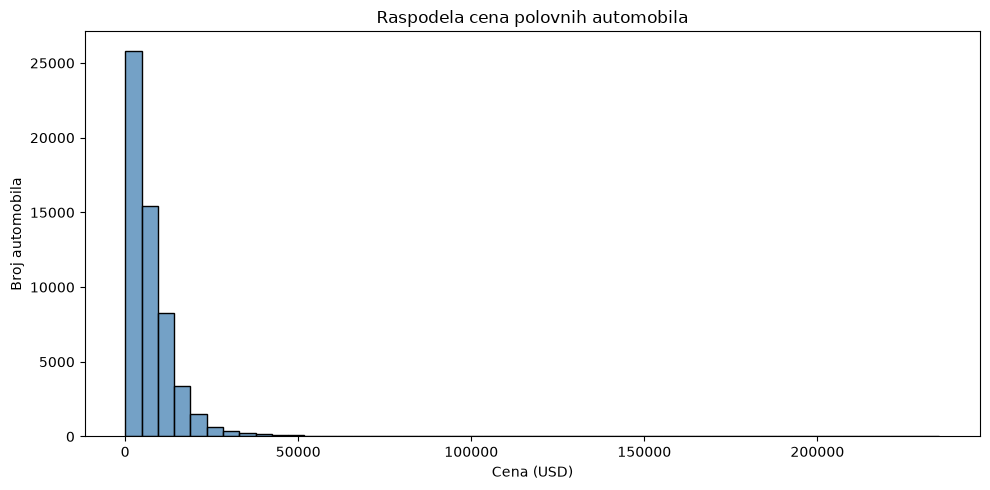

In [124]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="priceUSD",
    bins=50,
    color="steelblue"
)

plt.title("Raspodela cena polovnih automobila")
plt.xlabel("Cena (USD)")
plt.ylabel("Broj automobila")

plt.tight_layout()
plt.show()

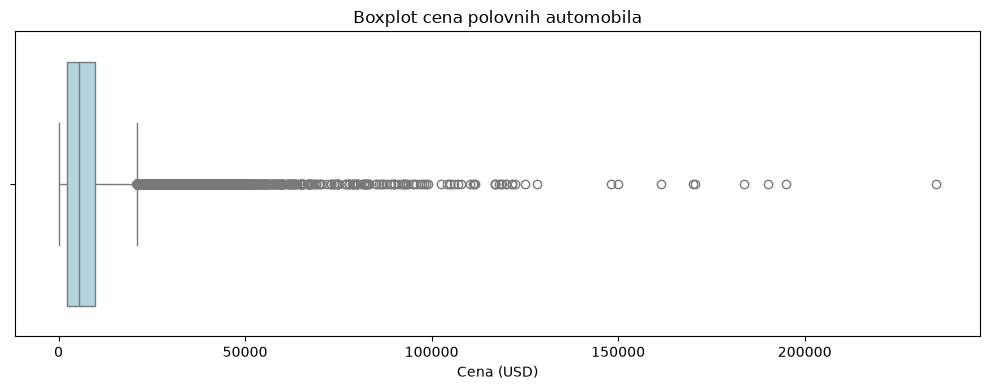

In [125]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="priceUSD",
    color="lightblue"
)

plt.title("Boxplot cena polovnih automobila")
plt.xlabel("Cena (USD)")

plt.tight_layout()
plt.show()

#### Zaključak analize ciljne promenljive

Analizom ciljne promenljive `priceUSD` utvrđeno je sledeće:

- Prosečna cena automobila iznosi približno **7.415 USD**.
- Medijana iznosi **5.350 USD**, što znači da polovina automobila ima cenu do ove vrednosti.
- Najniža zabeležena cena iznosi **48 USD**, a najviša **235.235 USD**.
- Prosečna cena veća je od medijane, što ukazuje na moguću pozitivnu asimetriju raspodele.
- Veliki raspon cena ukazuje na potrebu za dodatnom analizom potencijalno ekstremnih vrednosti.

U ovoj fazi ekstremne vrednosti neće biti uklonjene, jer je prethodno potrebno utvrditi da li predstavljaju greške u podacima ili realne tržišne cene.

Dobijeni rezultati biće važni prilikom kasnijeg čišćenja podataka i evaluacije regresionih modela.

### 1.5. Analiza numeričkih karakteristika

Pored ciljne promenljive `priceUSD`, skup podataka sadrži tri numeričke karakteristike:

- `year` — godina proizvodnje automobila.
- `mileage(kilometers)` — ukupna pređena kilometraža.
- `volume(cm3)` — zapremina motora izražena u kubnim centimetrima.

Cilj analize je ispitivanje osnovnih statističkih pokazatelja, raspodele vrednosti i mogućih ekstremnih ili nevalidnih podataka.

Rezultati će pomoći pri donošenju odluka o čišćenju podataka i kreiranju dodatnih karakteristika za regresione modele.

In [126]:
numeric_features = [
    "year",
    "mileage(kilometers)",
    "volume(cm3)"
]

df[numeric_features].describe()

,year,mileage(kilometers),volume(cm3)
count,56244.000000,5.624400e+04,56197.000000
mean,2003.454840,2.443956e+05,2104.860615
std,8.144247,3.210307e+05,959.201633
min,1910.000000,0.000000e+00,500.000000
25%,1998.000000,1.370000e+05,1600.000000
50%,2004.000000,2.285000e+05,1996.000000
75%,2010.000000,3.100000e+05,2300.000000
max,2019.000000,9.999999e+06,20000.000000


#### 1.5.1. Raspodela numeričkih karakteristika

Histogramima se prikazuje raspodela godina proizvodnje, kilometraže i zapremine motora.

Ova analiza omogućava uočavanje najčešćih vrednosti, asimetrije raspodele i potencijalno neuobičajenih podataka.

Posebnu pažnju potrebno je obratiti na veoma stare ili buduće godine proizvodnje, ekstremno velike kilometraže i neuobičajene zapremine motora.

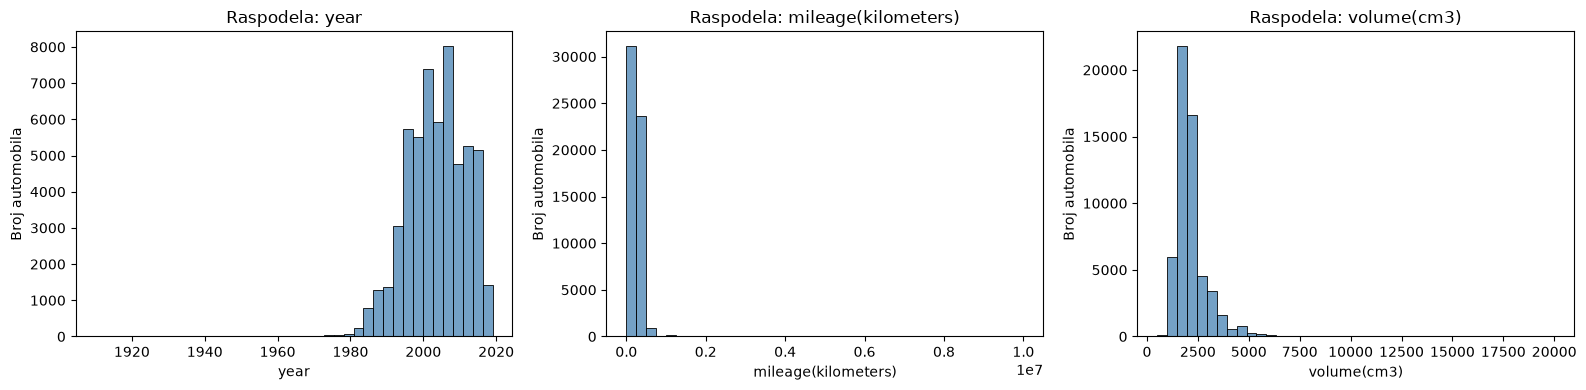

In [127]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, numeric_features):
    sns.histplot(
        data=df,
        x=column,
        bins=40,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Raspodela: {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Broj automobila")

plt.tight_layout()
plt.show()

#### 1.5.2. Identifikacija potencijalnih ekstremnih vrednosti

Boxplot grafikoni koriste se za vizuelno prepoznavanje potencijalnih ekstremnih vrednosti.

Ekstremne vrednosti mogu predstavljati stvarne karakteristike automobila, ali i greške prilikom unosa podataka.

U ovoj fazi podaci se samo analiziraju, bez uklanjanja ili izmene vrednosti.

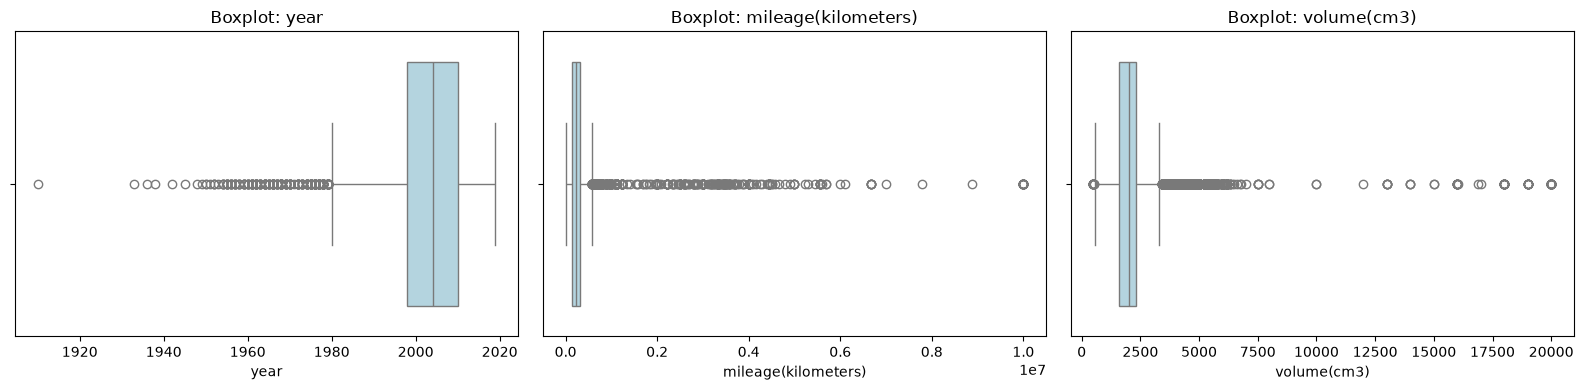

In [128]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, numeric_features):
    sns.boxplot(
        data=df,
        x=column,
        ax=ax,
        color="lightblue"
    )

    ax.set_title(f"Boxplot: {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

In [129]:
df[numeric_features].agg(["min", "max"])

,year,mileage(kilometers),volume(cm3)
min,1910,0.0,500.0
max,2019,9999999.0,20000.0


#### 1.5.3. Zaključak analize numeričkih karakteristika

Analizom numeričkih karakteristika utvrđeno je sledeće:

**Godina proizvodnje (`year`)**

- Godine proizvodnje kreću se od 1910. do 2019.
- Medijana iznosi 2004. godinu.
- U podacima nisu pronađene godine proizvodnje nakon 2026. godine.
- Veoma stara vozila mogu predstavljati specifičnu kategoriju automobila i zahtevaju pažnju prilikom analize.

**Kilometraža (`mileage(kilometers)`)**

- Medijana kilometraže iznosi 228.500 km.
- Minimalna vrednost iznosi 0 km.
- Maksimalna vrednost iznosi 9.999.999 km.
- Pronađeno je 190 vozila sa kilometražom od 0 km.
- Ekstremno visoke kilometraže zahtevaju dodatnu proveru jer mogu predstavljati greške pri unosu podataka.

**Zapremina motora (`volume(cm3)`)**

- Medijana zapremine motora iznosi 1.996 cm³.
- Minimalna vrednost iznosi 500 cm³.
- Maksimalna vrednost iznosi 20.000 cm³.
- U ovoj koloni nedostaje 47 vrednosti.
- Neuobičajeno velike zapremine motora zahtevaju dodatnu analizu.

**Opšti zaključak**

Numeričke karakteristike sadrže potencijalno ekstremne i neuobičajene vrednosti koje mogu uticati na kvalitet regresionih modela.

U ovoj fazi podaci se ne menjaju. Odluke o obradi nevalidnih i ekstremnih vrednosti biće donete tokom čišćenja podataka.

### 1.6. Analiza kategorijskih karakteristika

Skup podataka sadrži osam kategorijskih karakteristika:

- `make` — marka automobila.
- `model` — model automobila.
- `condition` — stanje vozila.
- `fuel_type` — tip goriva.
- `color` — boja automobila.
- `transmission` — tip menjača.
- `drive_unit` — tip pogona.
- `segment` — segment automobila.

Cilj ove analize je da se utvrdi broj jedinstvenih kategorija, njihova učestalost i eventualno prisustvo neuobičajenih ili nekonzistentnih vrednosti.

Rezultati će biti korisni prilikom čišćenja podataka i pripreme kategorijskih karakteristika za regresione modele.

In [130]:
categorical_features = [
    "make",
    "model",
    "condition",
    "fuel_type",
    "color",
    "transmission",
    "drive_unit",
    "segment"
]

df[categorical_features].nunique().sort_values(ascending=False)

model           1034
make              96
color             13
segment            9
drive_unit         4
condition          3
fuel_type          3
transmission       2
dtype: int64

#### 1.6.1. Učestalost kategorijskih vrednosti

Pored broja jedinstvenih kategorija, potrebno je analizirati koliko se često pojedine vrednosti pojavljuju u skupu podataka.

Metoda `value_counts()` omogućava prikaz broja pojavljivanja svake kategorije.

Posebna pažnja biće posvećena kolonama sa velikim brojem različitih vrednosti i kategorijama koje se veoma retko pojavljuju.

In [131]:
for column in categorical_features:
    print(f"\nKolona: {column}")
    print(df[column].value_counts(dropna=False).head(10))
    print("-" * 40)


Kolona: make
make
volkswagen       6861
audi             4030
bmw              4013
opel             3779
renault          3713
mercedes-benz    3541
ford             3078
peugeot          2876
nissan           2233
toyota           2177
Name: count, dtype: int64
----------------------------------------

Kolona: model
model
passat      2086
5-seriya    1476
a6          1276
golf        1070
astra       1013
e-klass      988
3-seriya     823
vectra       815
laguna       768
mondeo       731
Name: count, dtype: int64
----------------------------------------

Kolona: condition
condition
with mileage    55278
with damage       512
for parts         454
Name: count, dtype: int64
----------------------------------------

Kolona: fuel_type
fuel_type
petrol        36405
diesel        19792
electrocar       47
Name: count, dtype: int64
----------------------------------------

Kolona: color
color
black       12385
silver      10075
blue         8083
gray         5807
white        5292
green  

#### 1.6.2. Vizualizacija najčešćih kategorija

Za prikaz zastupljenosti kategorijskih vrednosti koriste se stubičasti grafikoni.

Kod kolona `make` i `model` prikazaćemo deset najčešćih vrednosti, jer ove kolone imaju veliki broj različitih kategorija.

Za ostale kategorijske karakteristike prikazaćemo sve vrednosti.

Cilj vizualizacije je da se lakše uoče dominantne kategorije i razlike u njihovoj učestalosti.

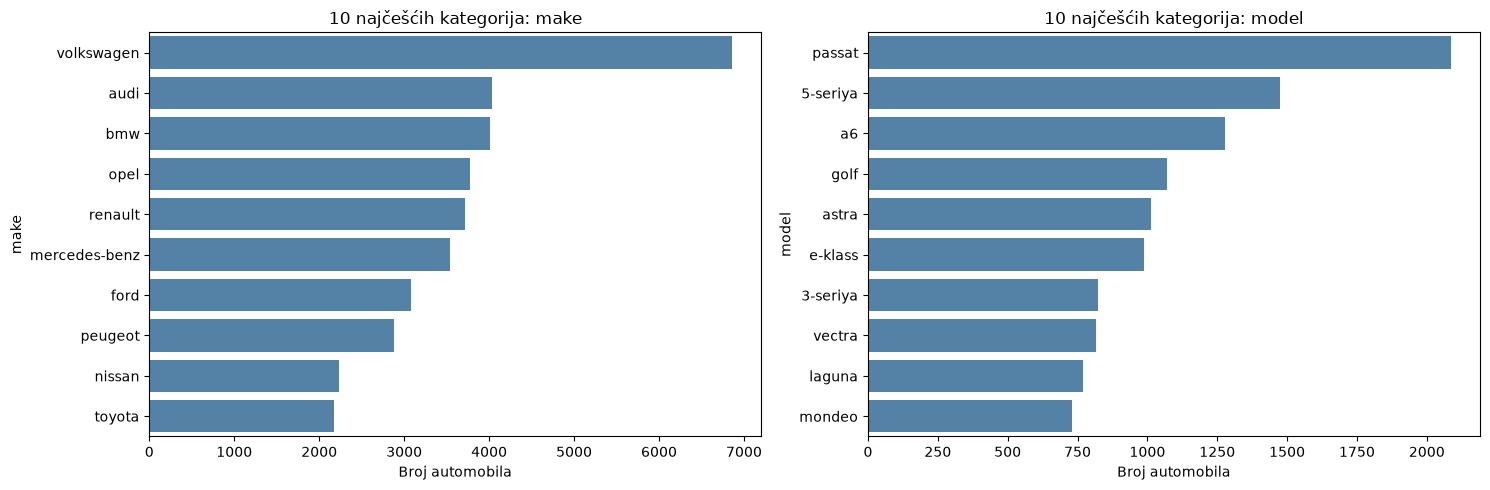

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, column in zip(axes, ["make", "model"]):
    counts = df[column].value_counts().head(10)

    sns.barplot(
        x=counts.values,
        y=counts.index,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"10 najčešćih kategorija: {column}")
    ax.set_xlabel("Broj automobila")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

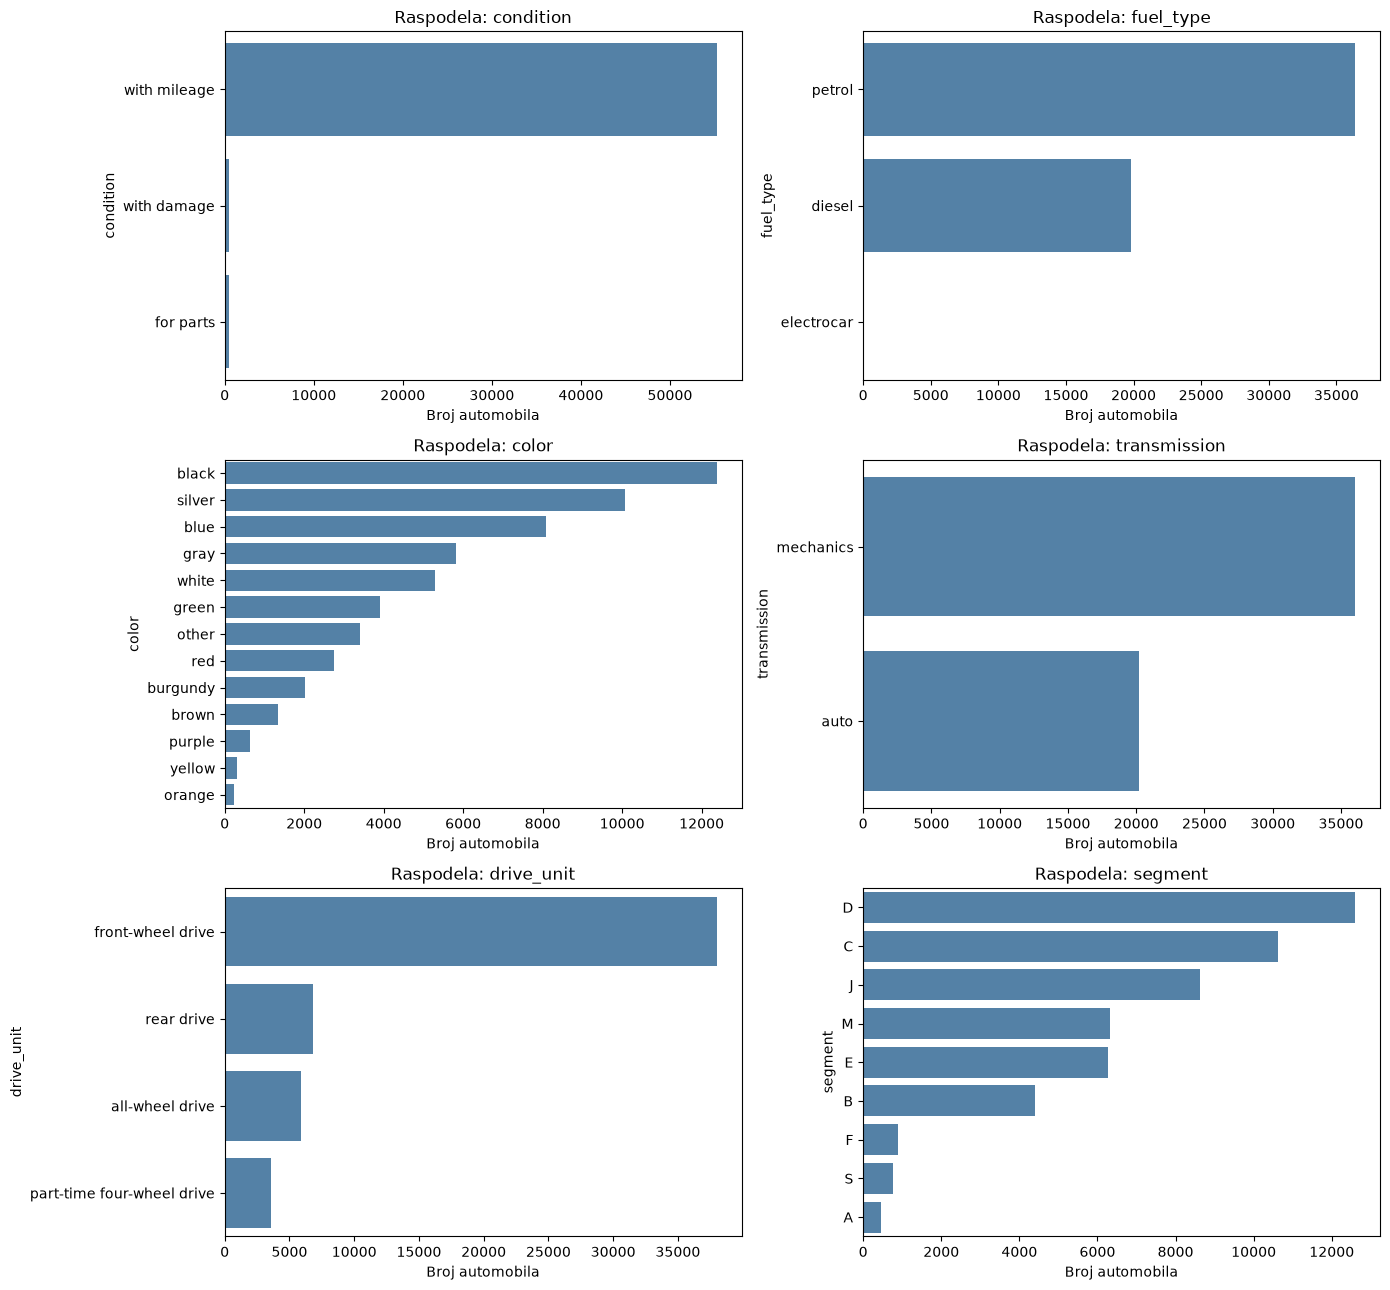

In [133]:
other_categorical_features = [
    "condition",
    "fuel_type",
    "color",
    "transmission",
    "drive_unit",
    "segment"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 13))

for ax, column in zip(axes.flat, other_categorical_features):
    counts = df[column].value_counts(dropna=False)

    sns.barplot(
        x=counts.values,
        y=counts.index.astype(str),
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Raspodela: {column}")
    ax.set_xlabel("Broj automobila")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

#### 1.6.3. Zaključak analize kategorijskih karakteristika

Analizom kategorijskih karakteristika utvrđeno je da se broj jedinstvenih vrednosti značajno razlikuje između kolona.

Najveći broj jedinstvenih vrednosti ima kolona `model` (1.034), zatim `make` (96). Ostale kategorijske kolone imaju između 2 i 13 različitih vrednosti.

Najzastupljenija marka automobila je `volkswagen` sa 6.861 vozilom, a slede `audi` sa 4.030 i `bmw` sa 4.013 vozila.

Veliki broj različitih modela automobila biće važan prilikom izbora načina kodiranja kategorijskih karakteristika u fazi pretprocesiranja.

U kolonama `drive_unit` i `segment` prethodno su identifikovane nedostajuće vrednosti, koje će biti obrađene u narednim fazama projekta.

U ovoj fazi kategorijske vrednosti nisu menjane.

### 1.7. Odnos karakteristika i ciljne promenljive

U ovom delu eksplorativne analize ispituje se povezanost karakteristika automobila sa ciljnom promenljivom `priceUSD`.

Cilj je da se utvrdi da li postoje obrasci koji mogu pomoći regresionim modelima da predvide cenu automobila.

Najpre će se analizirati odnos cene sa numeričkim karakteristikama:

- `year` — godina proizvodnje.
- `mileage(kilometers)` — kilometraža.
- `volume(cm3)` — zapremina motora.

Za analizu će se koristiti dijagrami rasipanja (*scatter plots*) i korelaciona matrica.

Važno je napomenuti da korelacija pokazuje statističku povezanost, ali ne dokazuje uzročno-posledičnu vezu.

#### 1.7.1. Odnos numeričkih karakteristika i cene

Dijagrami rasipanja prikazuju odnos između dve numeričke promenljive.

Na horizontalnoj osi prikazuje se karakteristika automobila, a na vertikalnoj osi njegova cena.

Na osnovu ovih grafikona moguće je uočiti potencijalne trendove, grupisanje podataka i ekstremne vrednosti.

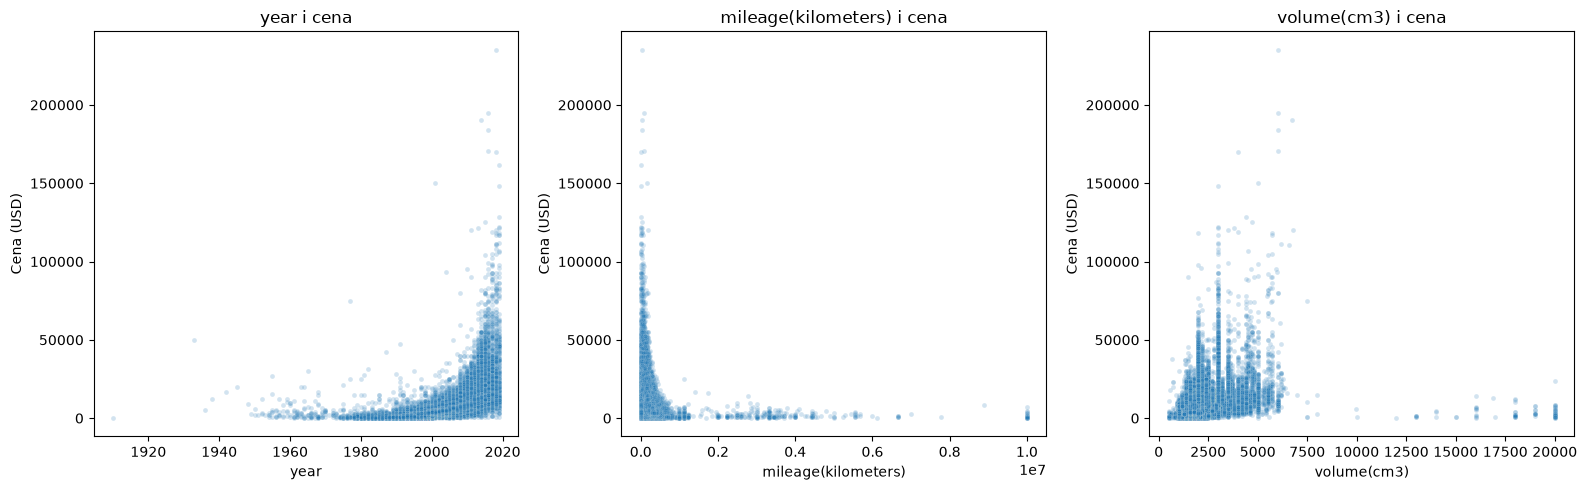

In [134]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, numeric_features):
    sns.scatterplot(
        data=df,
        x=column,
        y="priceUSD",
        alpha=0.2,
        s=12,
        ax=ax
    )

    ax.set_title(f"{column} i cena")
    ax.set_xlabel(column)
    ax.set_ylabel("Cena (USD)")

plt.tight_layout()
plt.show()

#### 1.7.2. Korelacija numeričkih karakteristika sa cenom

Korelacija pokazuje smer i jačinu linearne povezanosti između numeričkih promenljivih.

Pearsonov koeficijent korelacije ima vrednosti od -1 do 1:

- Vrednost bliska 1 označava snažnu pozitivnu linearnu povezanost.
- Vrednost bliska -1 označava snažnu negativnu linearnu povezanost.
- Vrednost bliska 0 označava slabu ili nepostojeću linearnu povezanost.

Korelacija će se izračunati između ciljne promenljive `priceUSD` i numeričkih karakteristika automobila.

In [135]:
correlation_columns = [
    "priceUSD",
    "year",
    "mileage(kilometers)",
    "volume(cm3)"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix

,priceUSD,year,mileage(kilometers),volume(cm3)
priceUSD,1.000000,0.605131,-0.170933,0.267553
year,0.605131,1.000000,-0.233049,0.027370
mileage(kilometers),-0.170933,-0.233049,1.000000,0.013452
volume(cm3),0.267553,0.027370,0.013452,1.000000


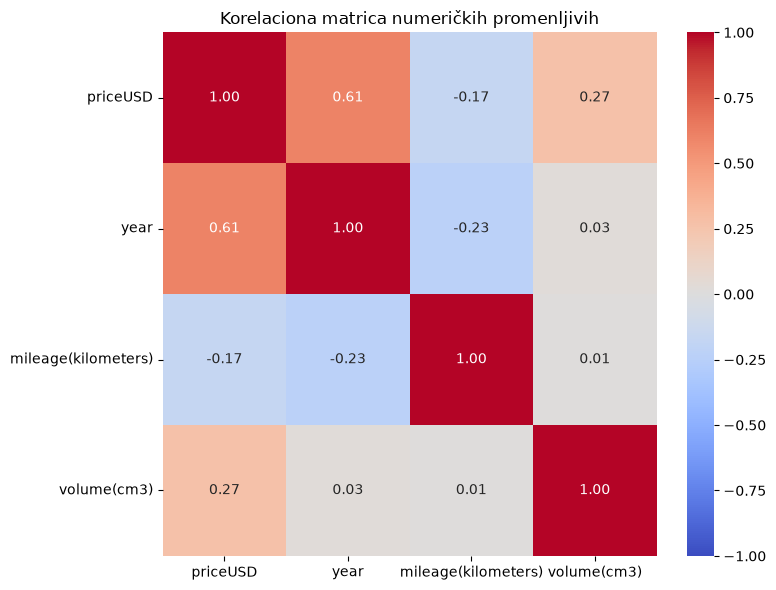

In [136]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Korelaciona matrica numeričkih promenljivih")
plt.tight_layout()
plt.show()

#### 1.7.3. Zaključak korelacione analize

Analizom Pearsonovih koeficijenata korelacije utvrđeno je sledeće:

- **Godina proizvodnje (`year`)** ima pozitivnu korelaciju sa cenom od **0,605**. Ovo je najjača linearna povezanost sa cenom među analiziranim numeričkim karakteristikama. Noviji automobili uglavnom imaju više cene.
- **Zapremina motora (`volume(cm3)`)** ima slabu pozitivnu korelaciju sa cenom od **0,268**.
- **Kilometraža (`mileage(kilometers)`)** ima slabu negativnu korelaciju sa cenom od **−0,171**, što ukazuje da automobili sa većom kilometražom uglavnom imaju nešto niže cene.

Dobijeni rezultati pokazuju da godina proizvodnje može biti posebno korisna karakteristika za predviđanje cene.

Ipak, slaba linearna korelacija ne znači da neka karakteristika nije korisna za regresioni model, jer između promenljivih mogu postojati i nelinearne veze.

Korelacija ne dokazuje uzročno-posledičnu vezu.

In [137]:
correlation_matrix["priceUSD"].sort_values(ascending=False)

priceUSD               1.000000
year                   0.605131
volume(cm3)            0.267553
mileage(kilometers)   -0.170933
Name: priceUSD, dtype: float64

### 1.8. Odnos kategorijskih karakteristika i cene

Kategorijske karakteristike predstavljaju osobine automobila izražene kroz različite kategorije, kao što su marka, model, tip goriva i menjač.

Za razliku od numeričkih karakteristika, njihova povezanost sa cenom ne može se direktno analizirati Pearsonovom korelacijom.

Zbog toga će se uporediti medijalne cene automobila između različitih kategorija.

Medijana se koristi zato što je manje osetljiva na ekstremno visoke ili niske cene u odnosu na aritmetičku sredinu.

In [138]:
top_makes = df["make"].value_counts().head(10).index

median_price_by_make = (
    df[df["make"].isin(top_makes)]
    .groupby("make")["priceUSD"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_make

make
toyota           8650.0
bmw              8300.0
mercedes-benz    7600.0
nissan           6200.0
volkswagen       6000.0
audi             5600.0
peugeot          4000.0
opel             4000.0
ford             3900.0
renault          3500.0
Name: priceUSD, dtype: float64

#### 1.8.1. Poređenje medijalnih cena po marki

Stubičastim grafikonom prikazuju se medijalne cene deset najzastupljenijih marki automobila.

Cilj je da se utvrdi da li postoje razlike u tipičnim cenama između marki i da li marka automobila može predstavljati korisnu karakteristiku za predviđanje cene.

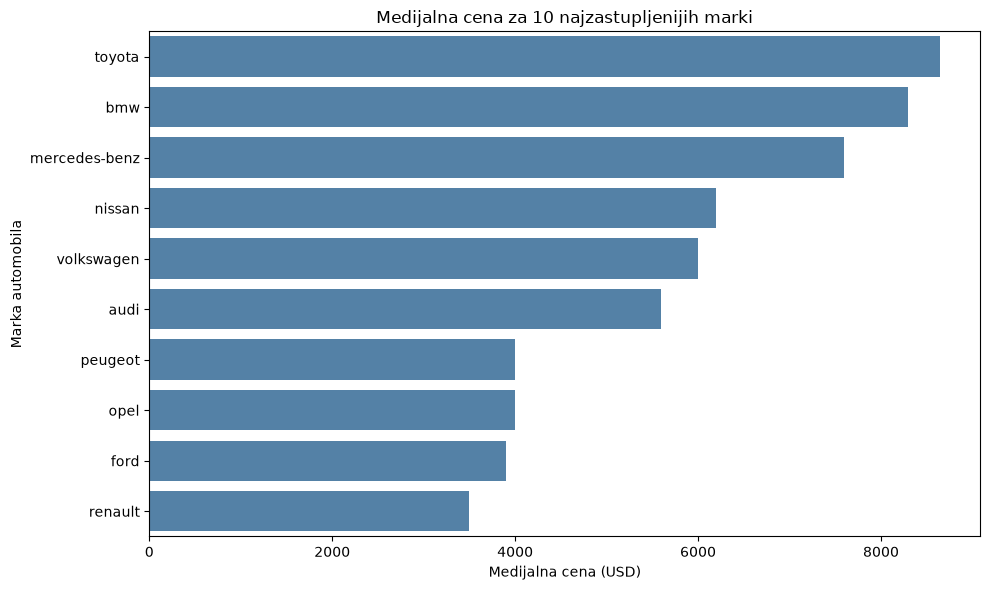

In [139]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=median_price_by_make.values,
    y=median_price_by_make.index,
    color="steelblue"
)

plt.title("Medijalna cena za 10 najzastupljenijih marki")
plt.xlabel("Medijalna cena (USD)")
plt.ylabel("Marka automobila")

plt.tight_layout()
plt.show()

#### Zaključak poređenja cena po markama

Analizom deset najzastupljenijih marki automobila utvrđene su razlike u njihovim medijalnim cenama.

Najvišu medijalnu cenu ima `toyota` (8.650 USD), zatim `bmw` (8.300 USD) i `mercedes-benz` (7.600 USD).

Najnižu medijalnu cenu među analiziranim markama ima `renault` (3.500 USD), dok `ford` ima medijalnu cenu od 3.900 USD.

Rezultati ukazuju na to da marka automobila može biti korisna karakteristika za predviđanje cene.

Ipak, razlike u cenama ne moraju biti posledica isključivo marke, već mogu zavisiti i od godine proizvodnje, kilometraže, modela i drugih karakteristika vozila.

#### 1.8.2. Poređenje cena po ostalim kategorijskim karakteristikama

Pored marke automobila, analiziraju se razlike u medijalnim cenama prema sledećim karakteristikama:

- `condition` — stanje vozila.
- `fuel_type` — tip goriva.
- `color` — boja automobila.
- `transmission` — tip menjača.
- `drive_unit` — tip pogona.
- `segment` — segment vozila.

Za svaku kategoriju izračunava se medijalna cena automobila.

Cilj je da se utvrdi da li postoje razlike u tipičnim cenama između pojedinih kategorija, bez donošenja zaključaka o uzročno-posledičnim vezama.

In [140]:
price_by_category = {}

for column in other_categorical_features:
    median_prices = (
        df.groupby(column, dropna=False)["priceUSD"]
        .median()
        .sort_values(ascending=False)
    )

    price_by_category[column] = median_prices

    print(f"\nKolona: {column}")
    print(median_prices)
    print("-" * 40)


Kolona: condition
condition
with mileage    5500.0
with damage     1000.0
for parts        400.0
Name: priceUSD, dtype: float64
----------------------------------------

Kolona: fuel_type
fuel_type
electrocar    15649.0
diesel         6300.0
petrol         4600.0
Name: priceUSD, dtype: float64
----------------------------------------

Kolona: color
color
brown       11300.0
black        8500.0
white        7300.0
gray         7000.0
orange       5000.0
silver       5000.0
other        5000.0
blue         3550.0
yellow       3000.0
burgundy     2500.0
purple       2350.0
red          2300.0
green        2150.0
Name: priceUSD, dtype: float64
----------------------------------------

Kolona: transmission
transmission
auto         9950.0
mechanics    3500.0
Name: priceUSD, dtype: float64
----------------------------------------

Kolona: drive_unit
drive_unit
all-wheel drive               12740.0
part-time four-wheel drive    10000.0
rear drive                     4500.0
front-wheel drive 

#### 1.8.3. Vizualizacija medijalnih cena po kategorijama

Stubičastim grafikonima prikazuju se medijalne cene automobila za različite kategorijske karakteristike.

Ova vizualizacija omogućava poređenje tipičnih cena između kategorija i prepoznavanje razlika koje bi mogle biti korisne za predviđanje cene.

Prikazane razlike treba tumačiti uz oprez, jer pojedine kategorije mogu sadržati znatno manje automobila od drugih.

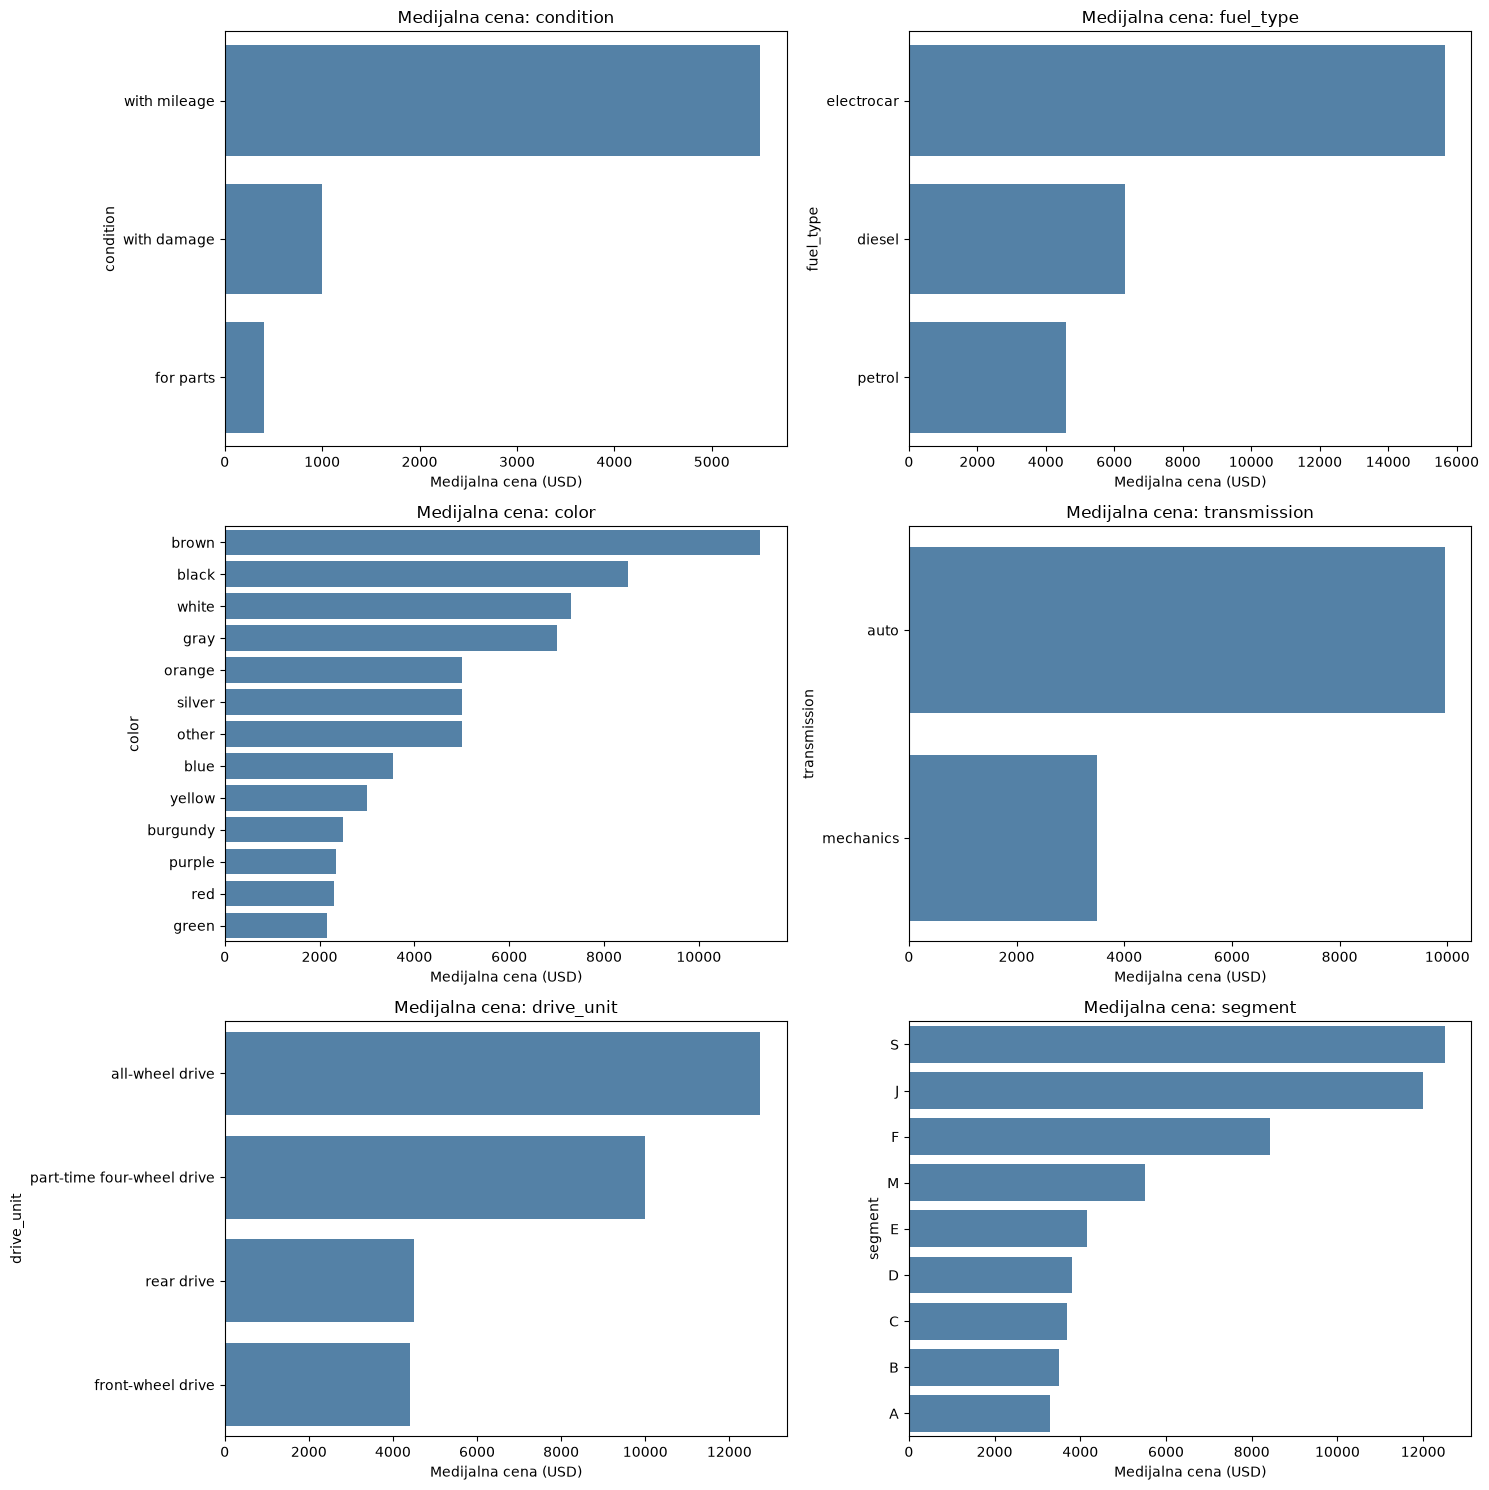

In [141]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for ax, column in zip(axes.flat, other_categorical_features):
    median_prices = price_by_category[column]

    sns.barplot(
        x=median_prices.values,
        y=median_prices.index.astype(str),
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Medijalna cena: {column}")
    ax.set_xlabel("Medijalna cena (USD)")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

#### 1.8.4. Zaključak poređenja cena po kategorijskim karakteristikama

Analizom medijalnih cena prema kategorijskim karakteristikama uočene su značajne razlike između pojedinih grupa automobila.

**Stanje vozila (`condition`)**

Automobili označeni kao `with mileage` imaju višu medijalnu cenu od oštećenih vozila (`with damage`) i vozila namenjenih za delove (`for parts`).

**Tip goriva (`fuel_type`)**

Električni automobili imaju najvišu medijalnu cenu, zatim slede dizel i benzinski automobili.

**Tip menjača (`transmission`)**

Automobili sa automatskim menjačem imaju višu medijalnu cenu od automobila sa manuelnim menjačem.

**Tip pogona (`drive_unit`)**

Vozila sa pogonom na sve točkove imaju više medijalne cene u odnosu na vozila sa prednjim i zadnjim pogonom.

**Segment vozila (`segment`)**

Najviše medijalne cene uočene su kod segmenata `S` i `J`, dok segmenti `A` i `B` imaju niže medijalne cene.

**Boja vozila (`color`)**

Uočene su razlike u medijalnim cenama između boja, ali one mogu biti povezane i sa drugim karakteristikama, kao što su marka, model i godina proizvodnje.

**Opšti zaključak**

Rezultati ukazuju da kategorijske karakteristike mogu sadržati korisne informacije za predviđanje cene automobila.

Ipak, prikazane razlike predstavljaju opisnu analizu i ne dokazuju da pojedina kategorija samostalno uzrokuje višu ili nižu cenu.

Tokom pretprocesiranja biće potrebno odgovarajuće kodirati kategorijske karakteristike kako bi ih regresioni modeli mogli koristiti.

#### 1.8.5. Provera zastupljenosti kategorija

Prilikom poređenja medijalnih cena važno je uzeti u obzir i broj automobila u svakoj kategoriji.

Kategorije sa malim brojem vozila mogu imati medijalne cene koje nisu dovoljno reprezentativne za širu grupu.

Zbog toga se analiziraju broj vozila i medijalna cena za svaku kategoriju.

In [142]:
for column in ["condition", "fuel_type", "transmission", "drive_unit", "segment"]:
    summary = (
        df.groupby(column, dropna=False)["priceUSD"]
        .agg(["count", "median"])
        .sort_values("median", ascending=False)
    )

    print(f"\nKolona: {column}")
    print(summary)
    print("-" * 40)


Kolona: condition
              count  median
condition                  
with mileage  55278  5500.0
with damage     512  1000.0
for parts       454   400.0
----------------------------------------

Kolona: fuel_type
            count   median
fuel_type                 
electrocar     47  15649.0
diesel      19792   6300.0
petrol      36405   4600.0
----------------------------------------

Kolona: transmission
              count  median
transmission               
auto          20188  9950.0
mechanics     36056  3500.0
----------------------------------------

Kolona: drive_unit
                            count   median
drive_unit                                
all-wheel drive              5890  12740.0
part-time four-wheel drive   3597  10000.0
rear drive                   6836   4500.0
front-wheel drive           38016   4400.0
NaN                          1905   3950.0
----------------------------------------

Kolona: segment
         count   median
segment                
S  

#### 1.8.6. Zaključak o zastupljenosti kategorija

Analizom broja vozila i medijalnih cena utvrđeno je da pojedine kategorije imaju značajno različitu zastupljenost u skupu podataka.

Kod tipa goriva najzastupljeniji su benzinski automobili (36.405), zatim dizel automobili (19.792), dok postoji samo 47 električnih automobila.

Iako električni automobili imaju najvišu medijalnu cenu (15.649 USD), njihov mali broj zahteva oprez pri tumačenju rezultata.

Automobili sa automatskim menjačem imaju medijalnu cenu od 9.950 USD, dok automobili sa manuelnim menjačem imaju medijalnu cenu od 3.500 USD.

Kod stanja vozila najzastupljenija su vozila označena kao `with mileage` (55.278), dok su oštećena vozila i vozila za delove znatno ređa.

Ovi rezultati pokazuju da je prilikom analize kategorijskih karakteristika važno posmatrati i medijalnu cenu i broj vozila u svakoj kategoriji.

Razlike između kategorija mogu biti povezane sa drugim karakteristikama automobila, pa ih ne treba tumačiti kao direktne uzročno-posledične veze.

### 1.9. Provera potencijalno problematičnih vrednosti

U završnom delu eksplorativne analize proverava se prisustvo potpuno dupliranih redova i potencijalno problematičnih numeričkih vrednosti.

Duplirani redovi mogu ukazivati na ponovljene zapise, ali ne moraju nužno predstavljati grešku.

Takođe, neuobičajeno visoke ili niske numeričke vrednosti mogu predstavljati stvarne karakteristike vozila ili greške pri unosu podataka.

U ovoj fazi samo se identifikuju potencijalni problemi. Obrada podataka biće sprovedena u narednoj fazi projekta.

In [143]:
duplicate_count = df.duplicated().sum()

print(f"Broj potpuno dupliranih redova: {duplicate_count}")

Broj potpuno dupliranih redova: 87


In [144]:
print("Automobili sa cenom <= 0:", (df["priceUSD"] <= 0).sum())
print("Automobili sa kilometražom < 0:", (df["mileage(kilometers)"] < 0).sum())
print("Automobili sa kilometražom = 0:", (df["mileage(kilometers)"] == 0).sum())
print("Automobili sa zapreminom motora <= 0:", (df["volume(cm3)"] <= 0).sum())
print("Automobili sa godinom proizvodnje > 2026:", (df["year"] > 2026).sum())

Automobili sa cenom <= 0: 0
Automobili sa kilometražom < 0: 0
Automobili sa kilometražom = 0: 190
Automobili sa zapreminom motora <= 0: 0
Automobili sa godinom proizvodnje > 2026: 0


#### 1.9.1. Zaključak provere kvaliteta podataka

Proverom kvaliteta skupa podataka identifikovano je **87 potpuno dupliranih redova**.

Nisu pronađene nepozitivne cene, negativne kilometraže, nepozitivne zapremine motora među poznatim vrednostima, niti godine proizvodnje nakon 2026. godine.

Identifikovano je **190 automobila sa kilometražom od 0 km**. Ove vrednosti zahtevaju dodatnu proveru, ali se ne mogu automatski smatrati greškama.

Prethodnom analizom takođe su uočene ekstremno visoke vrednosti kilometraže i zapremine motora, kao i nedostajuće vrednosti u kolonama `volume(cm3)`, `drive_unit` i `segment`.

Identifikovani problemi biće razmotreni tokom čišćenja i pretprocesiranja podataka.

U ovoj fazi nijedan red niti vrednost nisu izmenjeni ili uklonjeni.

## Poređenje regresionih modela

Za predviđanje cena polovnih automobila korišćena su tri regresiona algoritma:

- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor

Svi modeli trenirani su na istom trening skupu i evaluirani na istom test skupu, uz podelu podataka u odnosu 80:20.

### Rezultati evaluacije

| Model | MAE (USD) | RMSE (USD) | R² |
|---|---:|---:|---:|
| Linear Regression | 2089.01 | 4311.73 | 0.7230 |
| Decision Tree | 1394.65 | 3794.21 | 0.7855 |
| Random Forest | 1072.86 | 2957.47 | 0.8697 |

### Izbor najboljeg modela

Random Forest Regressor ostvario je najbolje rezultate, sa najmanjom prosečnom apsolutnom greškom (MAE) od približno 1073 USD i najvećom R² vrednošću od približno 0.87.

Zbog toga je izabran kao finalni model i sačuvan u fajlu `models/car_price_model.joblib`.

Sačuvani model uključuje i korake pretprocesiranja podataka.